# MGT5493 Programming in Business Analytics

#### Lab 3 — Exploratory Data Analysis & Visualization: Marketing Performance Analysis

#### Dataset: marketing_performance.csv

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
# load dataset and inspection
df = pd.read_csv("marketing_performance.csv")
print(df.head(5), 
      "\n", 
      "=" * 100, 
      "\n", 
      df.describe(),
      "\n")
print(df.info())

     Month Region    Channel    Spend  Leads    Sales  Impressions  Clicks
0  2024-01     UK     Search  7266.49     69   809.75      1997616   50992
1  2024-01     UK     Social  9815.07     59   352.64      3829279  136825
2  2024-01     UK      Email  7179.70     33   325.66      2487039   70458
3  2024-01     UK    Display  8284.50    200  2388.13      2648817   84297
4  2024-01     UK  Affiliate  8761.09    195  2138.92      2025596   96537 
               Spend       Leads        Sales   Impressions         Clicks
count    360.000000  360.000000   360.000000  3.600000e+02     360.000000
mean    8039.740889  114.383333  1341.318250  2.394418e+06   71569.463889
std     2359.915147   60.364148  1057.792328  8.604514e+05   39838.922638
min     1240.460000   17.000000    48.920000  3.252440e+05    8371.000000
25%     6448.415000   70.750000   587.720000  1.795931e+06   41074.000000
50%     8014.905000   99.000000  1048.940000  2.305104e+06   62349.000000
75%     9394.600000  149.00000

In [ ]:
# data cleaning 
print("Number of NaN in Region column:",df["Region"].isnull().sum())

df[df["Region"].isnull()]

Number of NaN in Region column: 90


,Month,Region,Channel,Spend,Leads,Sales,Impressions,Clicks
15,2024-01,NaN,Search,6583.22,109,2749.65,1558122,35461
16,2024-01,NaN,Social,6671.63,42,262.79,1740284,76215
17,2024-01,NaN,Email,6094.51,85,1112.67,1858528,20315
18,2024-01,NaN,Display,5897.63,57,665.18,1689016,71916
19,2024-01,NaN,Affiliate,8892.82,181,1147.88,2296533,48856
...,...,...,...,...,...,...,...,...
355,2025-06,NaN,Search,4792.13,46,524.30,1574137,74269
356,2025-06,NaN,Social,8732.69,87,1498.24,1792841,77495
357,2025-06,NaN,Email,9790.49,301,3746.06,3105103,150911
358,2025-06,NaN,Display,6775.37,74,1252.19,2629155,39363


In [15]:
# data cleaning 
df["Region"] = df["Region"].fillna("Unknown")
df["Region"].isnull().sum()

np.int64(0)

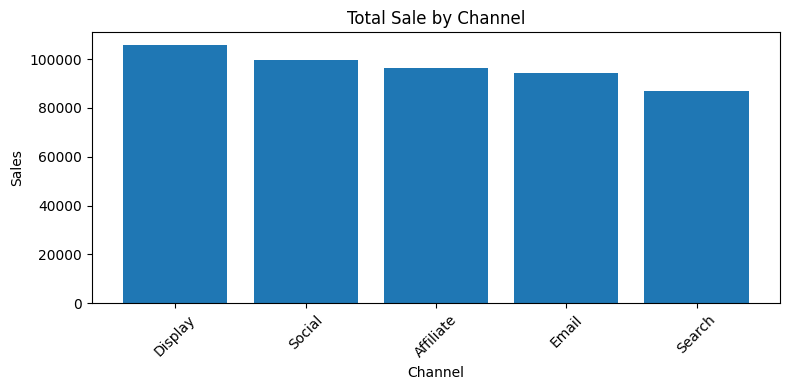

In [19]:
# Total sales by channel 

sales_channel = (
    df.groupby("Channel", as_index= False)['Sales']
    .sum()
    .sort_values(by = "Sales", ascending = False)
)

# plot sales of channel by bar chat:
plt.figure(figsize = (8,4))
plt.bar(sales_channel["Channel"], sales_channel["Sales"])
plt.title("Total Sale by Channel")
plt.xlabel("Channel")
plt.ylabel("Sales")
plt.xticks(rotation = 45)
plt.tight_layout()
plt.show()

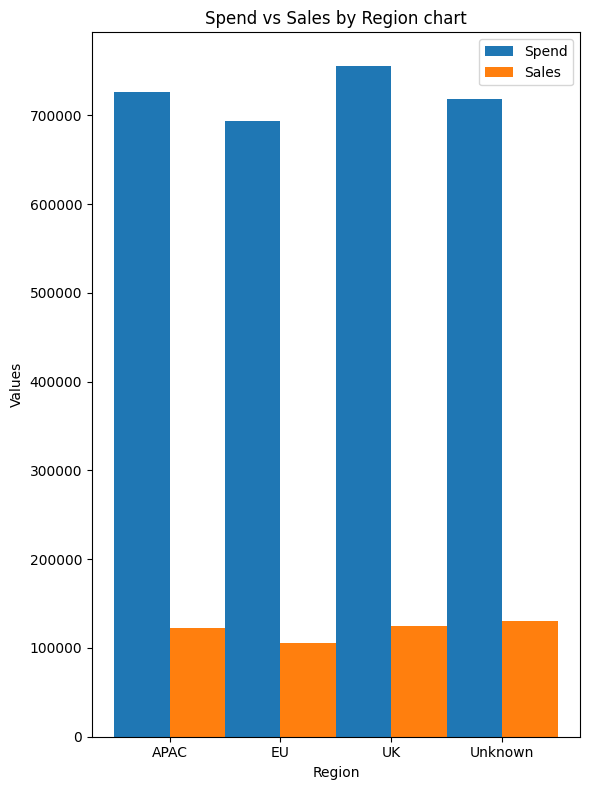

In [21]:
# spend vs. sales by region (side by side bars chart)

## table created by aggreation 
region_sum = df.groupby("Region")[["Spend", "Sales"]].sum()

## plot side by side bars
x = np.arange(len(region_sum.index))
width = 0.5

figure, ax = plt.subplots (figsize = (6,8))
ax.bar(x - width/2, region_sum['Spend'].values, width, label = 'Spend')
ax.bar(x + width/2, region_sum['Sales'].values, width, label = 'Sales')
ax.set_xticks(x)
ax.set_xticklabels(region_sum.index)
ax.set_title("Spend vs Sales by Region chart")
ax.set_xlabel("Region")
ax.set_ylabel("Values")
ax.legend()
plt.tight_layout()
plt.show()